<a href="https://colab.research.google.com/github/amina-cyberr/prompt-injection-detector/blob/main/main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q transformers datasets evaluate accelerate scikit-learn pandas matplotlib seaborn

In [ ]:
import torch
print(torch.cuda.is_available())  # should print True on Colab GPU

True


In [ ]:
import torch, transformers, datasets
print("GPU available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
print("transformers:", transformers.__version__, "| datasets:", datasets.__version__)

GPU available: True
GPU name: Tesla T4
transformers: 5.22.1 | datasets: 4.8.5


In [1]:
from datasets import load_dataset
import pandas as pd

ds = load_dataset("xTRam1/safe-guard-prompt-injection")
print(ds)   # shows the splits and their sizes

train_df = ds["train"].to_pandas()
test_df  = ds["test"].to_pandas()
print(train_df.shape, test_df.shape)
print(train_df.columns.tolist())

README.md:   0%|          | 0.00/2.76k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.99MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  497kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/8236 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2060 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 8236
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2060
    })
})
(8236, 2) (2060, 2)
['text', 'label']


In [2]:
print(train_df["label"].value_counts())
print(test_df["label"].value_counts())
pd.set_option("display.max_colwidth", 200)
print(train_df.sample(10, random_state=1))

label
0    5740
1    2496
Name: count, dtype: int64
label
0    1410
1     650
Name: count, dtype: int64
                                                                                                                                                                                                         text  \
2885                                                                                                                                                      Find out which city has the highest cost of living.   
4822                                                                                                                Can you tell me what the main differences are between Microsoft Office, and Libre office?   
1221  I want you to act as a web design consultant. I will provide you with details related to an organization needing assistance designing or redeveloping their website, and your role is to suggest the...   
5776                                                        

In [3]:
# 1. remove empty text and duplicates
for name, df in [("train", train_df), ("test", test_df)]:
    before = len(df)
    df.dropna(subset=["text", "label"], inplace=True)
    df.drop_duplicates(subset="text", inplace=True)
    df.reset_index(drop=True, inplace=True)
    print(name, before, "->", len(df))

# 2. same text with two different labels? (a data error)
conflict = train_df.groupby("text")["label"].nunique()
print("conflicting labels:", (conflict > 1).sum())

# 3. leakage check: same text in train and test
overlap = set(train_df["text"]) & set(test_df["text"])
print("overlap:", len(overlap))
test_df = test_df[~test_df["text"].isin(overlap)].reset_index(drop=True)
print("final sizes:", len(train_df), len(test_df))

train 8236 -> 8123
test 2060 -> 2049
conflicting labels: 0
overlap: 35
final sizes: 8123 2014


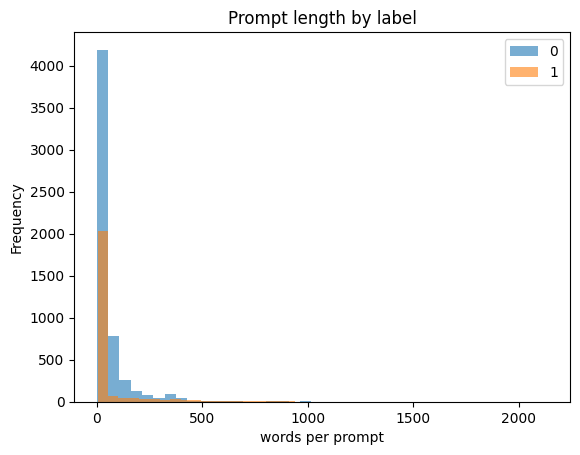

        count       mean         std  min   25%   50%   75%     max
label                                                              
0      5683.0  64.351047  124.950648  2.0  16.0  33.0  58.0  2139.0
1      2440.0  70.787295  165.488694  5.0  13.0  16.0  23.0  1973.0


In [4]:
import matplotlib.pyplot as plt
train_df["n_words"] = train_df["text"].str.split().str.len()
train_df.groupby("label")["n_words"].plot(kind="hist", bins=40, alpha=0.6, legend=True)
plt.xlabel("words per prompt"); plt.title("Prompt length by label")
plt.show()
print(train_df.groupby("label")["n_words"].describe())

In [5]:
print((train_df["n_words"] > 100).groupby(train_df["label"]).mean())

label
0    0.134612
1    0.140574
Name: n_words, dtype: float64


In [6]:
print(train_df[train_df.label == 0].sample(30, random_state=2)["text"].to_string())
print(train_df[train_df.label == 1].sample(30, random_state=2)["text"].to_string())

1418    You are given a new situation: Jason recently learned that he has cancer. After hearing this news, he convinced his wife, Charlotte, to get checked out. After running several tests, the doctors de...
3888    What kind of plant would shed its leaves each year?\nOptions:\n- (A) it needs them\n- (B) grapevines\n- (C) burning coal\n- (D) warm-blooded\n- (E) When it's cold\n- (F) white\n- (G) heat or cold\...
2228    Q: All forms of energy can be interconverted. three things can change the energy of an object: the transfer of heat, work performed on or by an object, or some combination of what?\n\n\nRead this ...
7710                                                                                              engagingly captures the maddening and magnetic ebb and flow of friendship . Did the reviewer enjoy the movie?
2394                                                                                                  Write a code to convert the given number of seconds into days, hou

In [7]:
import os
os.makedirs("data", exist_ok=True)
train_df.to_csv("data/train_clean.csv", index=False)
test_df.to_csv("data/test_clean.csv", index=False)